# EDA Visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent style for readable charts
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv("data.csv", encoding="cp1252")

# Prepare useful columns for analysis
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df["LineValue"] = df["Quantity"] * df["UnitPrice"]
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)

print("Dataset shape:", df.shape)
print(df.head())  

Dataset shape: (541909, 10)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  LineValue  \
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom      15.30   
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom      20.34   
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom      22.00   
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom      20.34   
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom      20.34   

  InvoiceMonth  
0      2010-12  
1      2010-12  
2      2010-12  
3      2010-12  
4  

## Histogram — Distribution of quantity

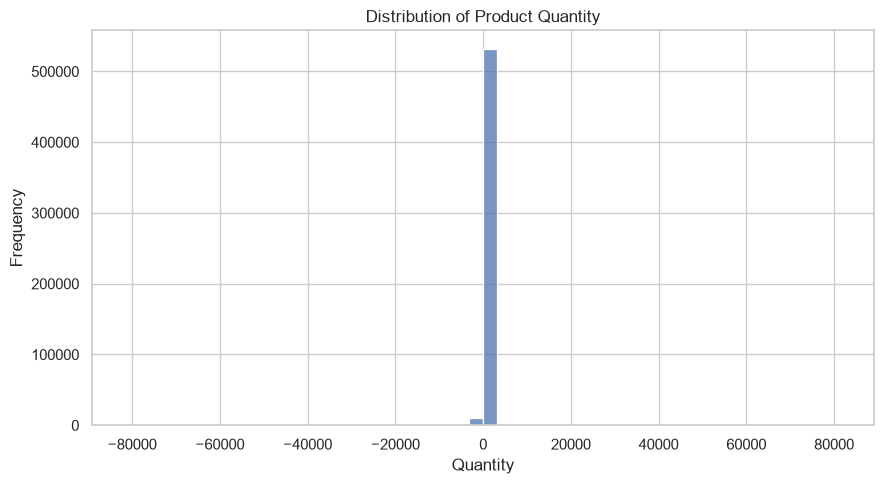

In [2]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="Quantity", bins=50)

plt.title("Distribution of Product Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Box plot — Detect potential outliers
#### Why select it? 
A box plot summarizes the median, quartiles, spread, and potential outliers of a numerical feature.

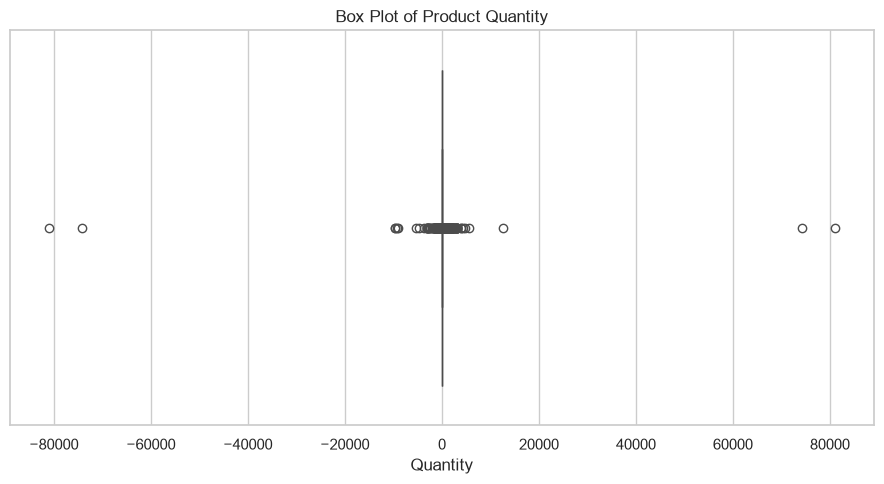

In [3]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Quantity")

plt.title("Box Plot of Product Quantity")
plt.xlabel("Quantity")
plt.tight_layout()
plt.show()

## Bar chart — Average line value by country
#### Why select it?
A bar chart compares a numerical summary across categories. Here, we compare the average calculated line value for the ten countries with the most records.

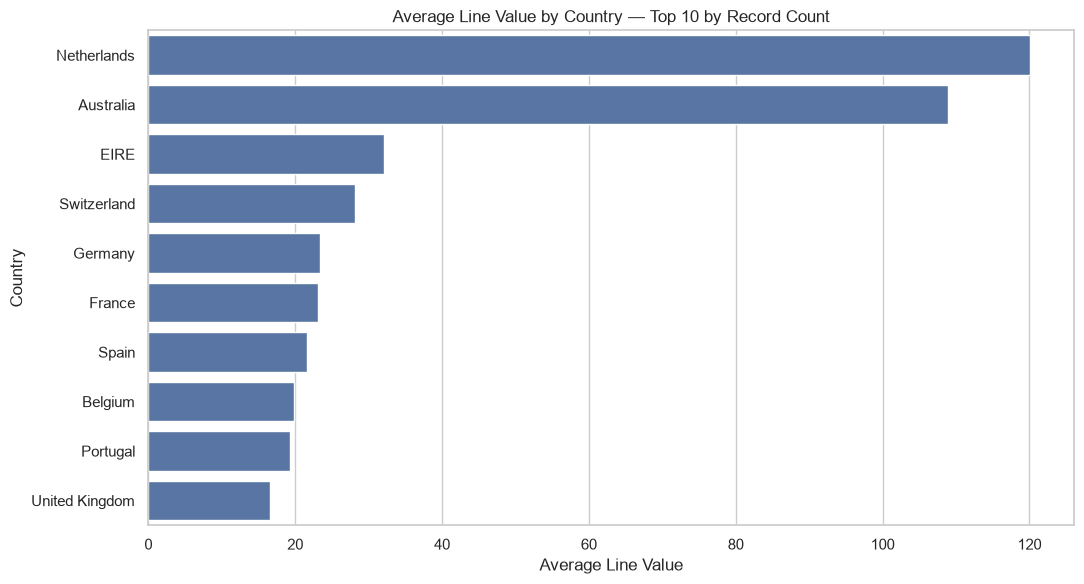

In [4]:
top_countries = df["Country"].value_counts().head(10).index

country_values = (
    df[df["Country"].isin(top_countries)]
    .groupby("Country")["LineValue"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=country_values.values,
    y=country_values.index
)

plt.title("Average Line Value by Country — Top 10 by Record Count")
plt.xlabel("Average Line Value")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## Count plot — Number of records by country
#### Why select it?
A count plot compares how frequently categories appear. It helps identify which countries contribute the most records to the dataset.

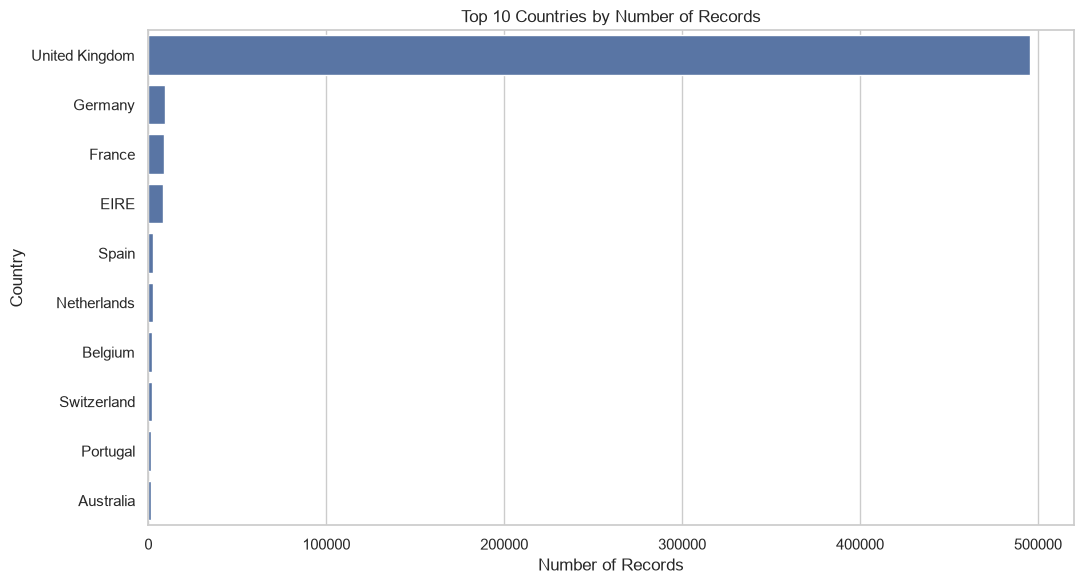

In [5]:
top_countries = df["Country"].value_counts().head(10).index
country_df = df[df["Country"].isin(top_countries)]

plt.figure(figsize=(11, 6))

sns.countplot(
    data=country_df,
    y="Country",
    order=country_df["Country"].value_counts().index
)

plt.title("Top 10 Countries by Number of Records")
plt.xlabel("Number of Records")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## Scatter plot — Quantity versus unit price
#### Why select it? 
A scatter plot helps us examine the relationship between two numerical variables and identify unusual combinations.

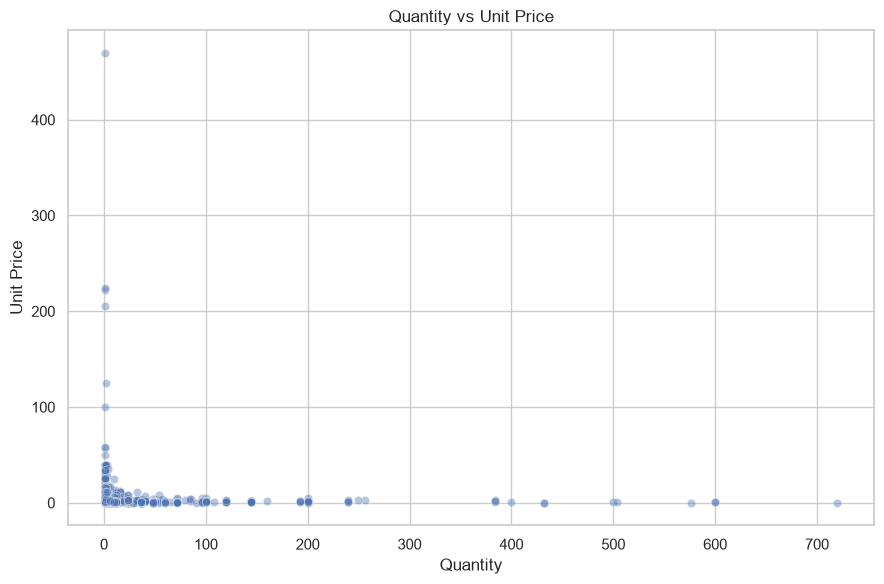

In [6]:
scatter_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
][["Quantity", "UnitPrice"]].dropna()

scatter_df = scatter_df.sample(
    n=min(5000, len(scatter_df)),
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=scatter_df,
    x="Quantity",
    y="UnitPrice",
    alpha=0.4
)

plt.title("Quantity vs Unit Price")
plt.xlabel("Quantity")
plt.ylabel("Unit Price")
plt.tight_layout()
plt.show()

## Line plot — Monthly transaction-line value
#### Why select it? 
A line plot is useful for time-based data. It helps reveal changes, trends, and recurring patterns over time.

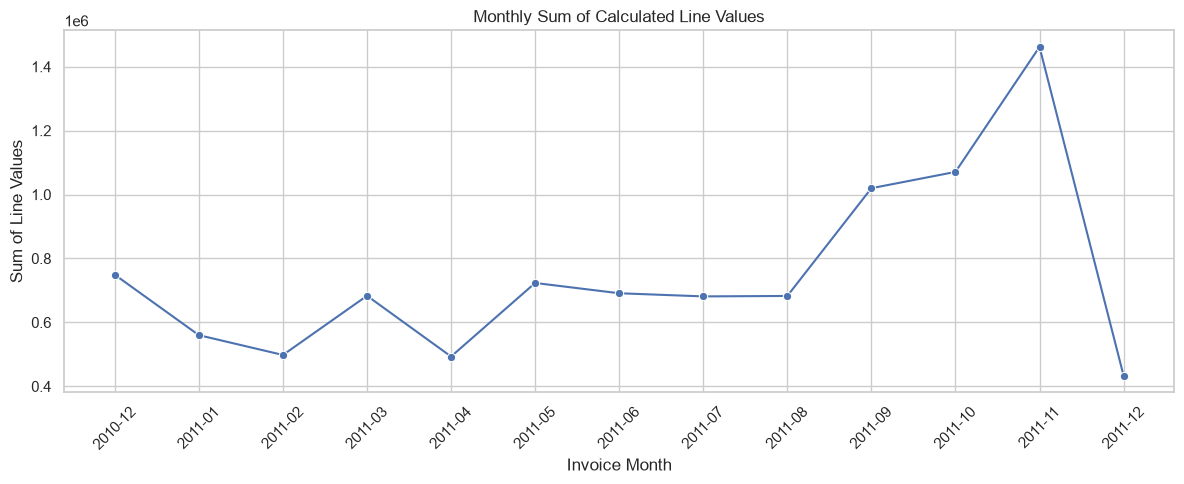

In [7]:
monthly_values = (
    df.dropna(subset=["InvoiceDate"])
    .groupby("InvoiceMonth")["LineValue"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_values.index,
    y=monthly_values.values,
    marker="o"
)

plt.title("Monthly Sum of Calculated Line Values")
plt.xlabel("Invoice Month")
plt.ylabel("Sum of Line Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Violin plot — Quantity distribution by country
#### Why select it? 
A violin plot shows the distribution and density of a numerical variable across categories. It can reveal differences that a simple bar chart cannot show.

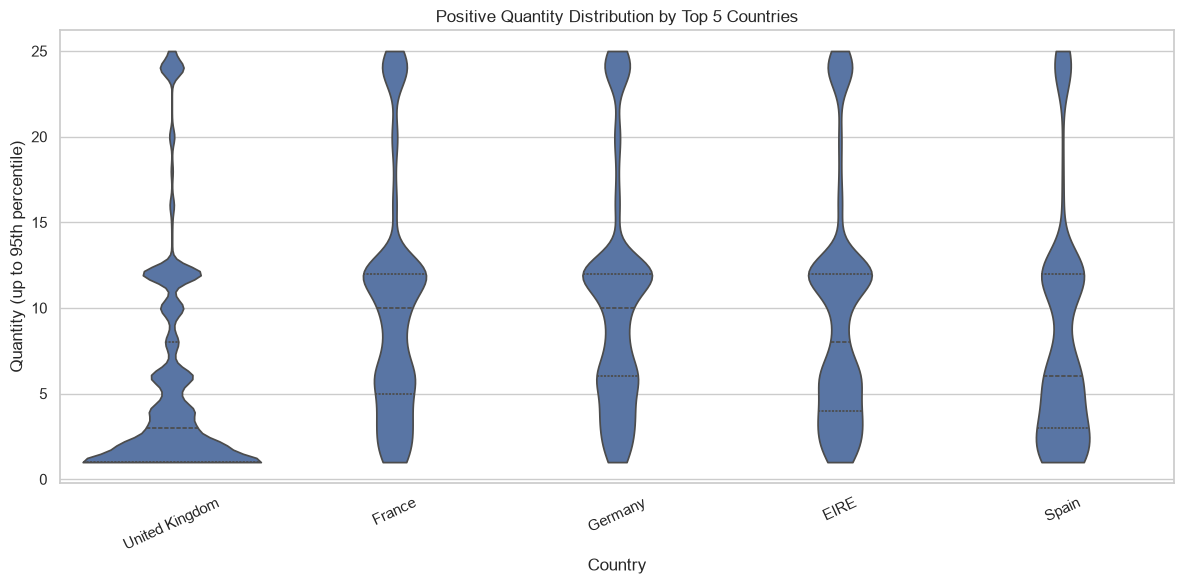

In [8]:
top5 = df["Country"].value_counts().head(5).index

violin_df = df[
    df["Country"].isin(top5) &
    (df["Quantity"] > 0)
][["Country", "Quantity"]].dropna()

upper = violin_df["Quantity"].quantile(0.95)
violin_df = violin_df[violin_df["Quantity"] <= upper]

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=violin_df,
    x="Country",
    y="Quantity",
    inner="quartile",
    cut=0
)

plt.title("Positive Quantity Distribution by Top 5 Countries")
plt.xlabel("Country")
plt.ylabel("Quantity (up to 95th percentile)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## Pair plot — Relationships among numerical features
#### Why select it?
A pair plot provides several views of numerical features in one figure. It helps you explore relationships and distributions before selecting features for a model.

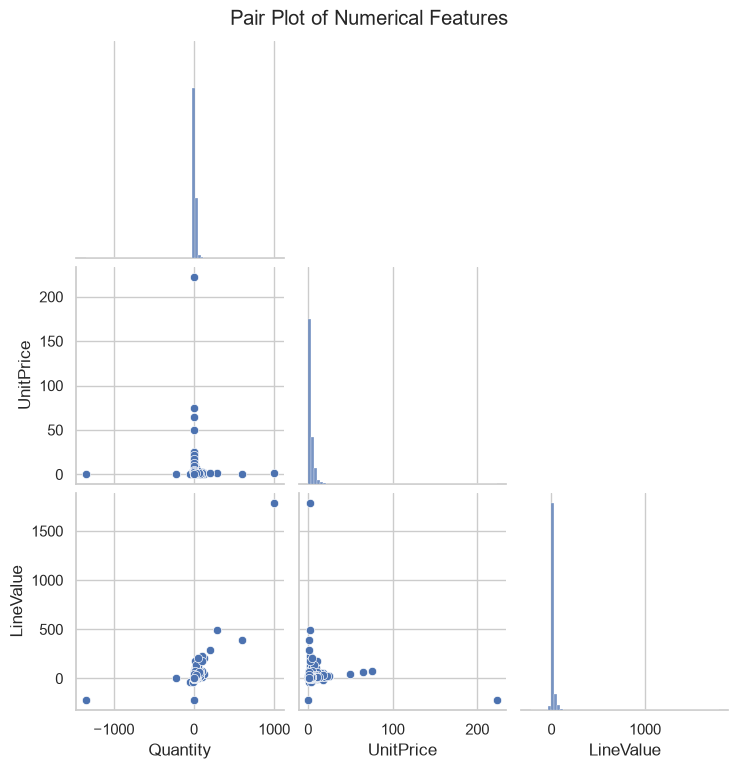

In [9]:
pair_df = df[["Quantity", "UnitPrice", "LineValue"]].dropna()

pair_df = pair_df.sample(
    n=min(1000, len(pair_df)),
    random_state=42
)

sns.pairplot(
    pair_df,
    diag_kind="hist",
    corner=True
)

plt.suptitle("Pair Plot of Numerical Features", y=1.02)
plt.show()

## Heatmap — Correlation between numerical features
#### Why select it?
A heatmap summarizes pairwise correlations, making it easier to spot numerical features that move together

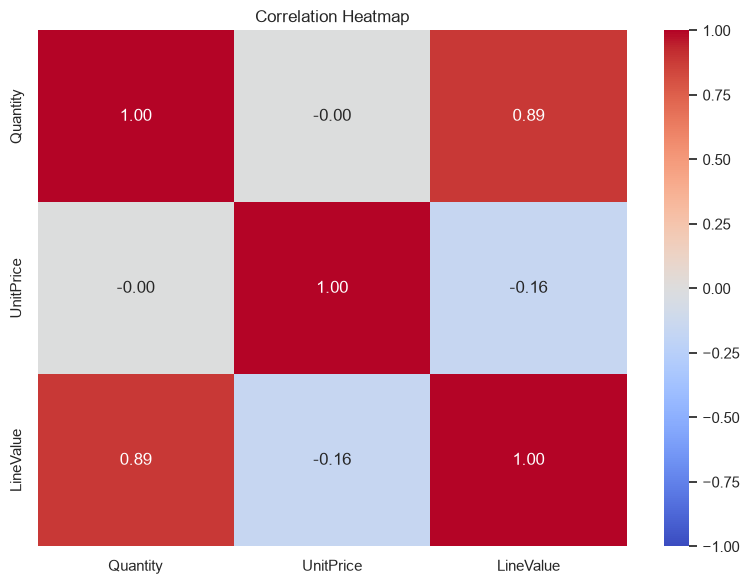

In [10]:
corr_df = df[
    ["Quantity", "UnitPrice", "LineValue"]
].dropna()

correlation = corr_df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Distribution plot — Density of unit prices
#### Why select it? 
A distribution plot helps examine the shape of a numerical feature. A histogram shows counts in bins, while a KDE curve estimates the distribution's density.

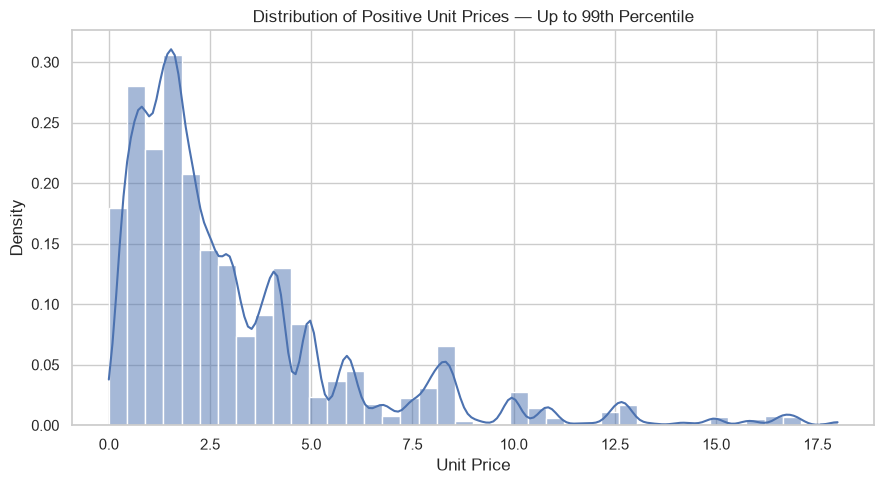

In [11]:
prices = df.loc[
    df["UnitPrice"] > 0, "UnitPrice"
].dropna()

price_limit = prices.quantile(0.99)
price_view = prices[prices <= price_limit]

plt.figure(figsize=(9, 5))

sns.histplot(
    price_view,
    bins=40,
    stat="density",
    kde=True
)

plt.title("Distribution of Positive Unit Prices — Up to 99th Percentile")
plt.xlabel("Unit Price")
plt.ylabel("Density")
plt.tight_layout()
plt.show()